In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


In [2]:
train_set = pd.read_csv('../wet1/prepared_train_data_try.csv')
test_set = pd.read_csv('../wet1/prepared_test_data_try.csv')
# train_set = pd.read_csv('train_data_eden.csv')
# test_set = pd.read_csv('test_data_eden.csv')


In [3]:
from sklearn.neighbors import KNeighborsClassifier
XTrainSetPcr26, YTrainSetPcr26 = train_set[["PCR_02", "PCR_06"]], train_set["spread"]
XTestSetPcr26, YTestSetPcr26 = test_set[["PCR_02", "PCR_06"]], test_set["spread"]



In [4]:
clf = KNeighborsClassifier(n_neighbors=1)
clf.fit(X= XTrainSetPcr26, y=YTrainSetPcr26)

KNeighborsClassifier(n_neighbors=1)

In [5]:
def visualize_clf(clf, X, Y, title, 
                  xlabel, ylabel,
                  marker_size=50,
                  grid_length=300,
                  linewidths=None):
    import matplotlib.pyplot as plt
    import pandas as pd
    from matplotlib.colors import ListedColormap
    
    if isinstance(X, pd.DataFrame):
        X = X.to_numpy()
        
    # For internal use here, make sure labels are 0 and 1
    Y = np.ravel(Y).astype(int)
    labels = set(Y)
    assert len(labels) == 2, "Can only visualize two unique labels"

    if labels == set([-1,1]):
      Y = (Y + 1) // 2
      labels = set(Y)
    
    assert labels == set([0,1]), "Could not handle given labels"

    plt.figure(figsize=(8, 8))

    # Parameters
    n_classes = 2
    markers = ["D", "o"]
    palette = sns.color_palette("hls", 2)
    custom_cmap = ListedColormap(palette.as_hex())

    x_delta = np.abs(X[:, 0].max() - X[:, 0].min()) * 0.1
    y_delta = np.abs(X[:, 1].max() - X[:, 1].min()) * 0.1
    x_min, x_max = X[:, 0].min() - x_delta, X[:, 0].max() + x_delta
    y_min, y_max = X[:, 1].min() - y_delta, X[:, 1].max() + y_delta
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_length),
                         np.linspace(y_min, y_max, grid_length))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    cs = plt.contourf(xx, yy, Z, cmap=custom_cmap, alpha=0.35)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(alpha=0.75)

    # Plot the training points
    for i, color, marker in zip(labels, palette, markers):
        idx = np.where(Y == i)
        plt.scatter(X[idx, 0], X[idx, 1], color=color,
                    marker=marker,
                    edgecolor='white', s=marker_size,
                    linewidths=linewidths)

    plt.title(title, fontsize=20)
    plt.axis("tight")
    plt.show()
   

/home/dandan/.local/lib/python3.10/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


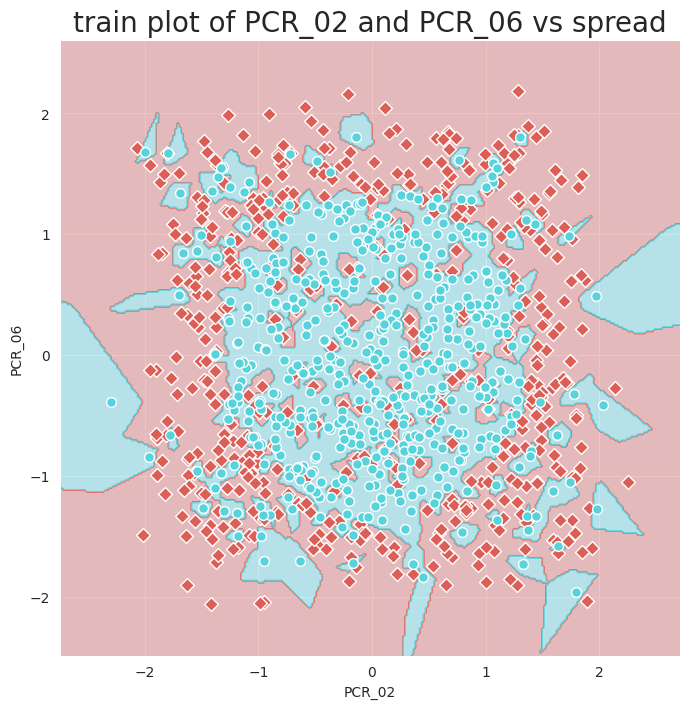

In [6]:
visualize_clf(clf,
              XTrainSetPcr26, YTrainSetPcr26,
              title="train plot of PCR_02 and PCR_06 vs spread"
              , xlabel="PCR_02", ylabel="PCR_06")

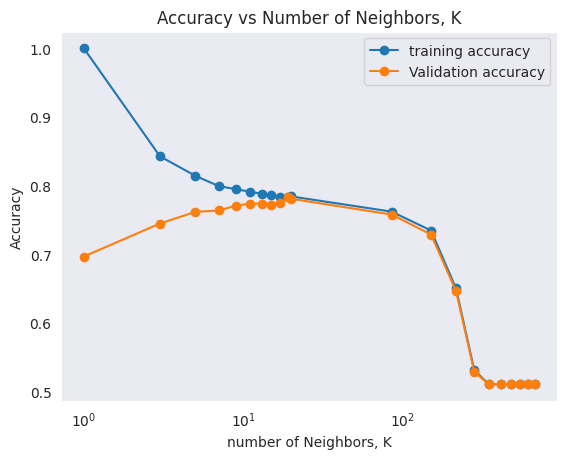

In [7]:
from sklearn.model_selection import cross_validate
k_list = list(range(1, 20, 2)) + list(range(20, 695, 65))

train_scores_mean = []
valid_scores_mean = []

for k in k_list:
    clf = KNeighborsClassifier(n_neighbors=k)
    cv_scores = cross_validate(estimator=clf,X=XTrainSetPcr26, y=YTrainSetPcr26,
                            cv=8, n_jobs=None, return_train_score=True, scoring='accuracy')
    train_scores_mean.append(np.mean(cv_scores['train_score']))
    valid_scores_mean.append(np.mean(cv_scores['test_score'])) 
    
plt.semilogx(k_list, train_scores_mean, label="training accuracy", marker="o")
plt.semilogx(k_list, valid_scores_mean, label="Validation accuracy", marker="o")
plt.xlabel("number of Neighbors, K")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Number of Neighbors, K")
plt.legend()
plt.grid()
plt.show()

    


In [8]:
best_k = k_list[np.argmax(valid_scores_mean)]
for k, train_score, validation_score in zip(k_list, train_scores_mean, valid_scores_mean):
    if k == best_k:
     print(f"k: {k}, train acc: {train_score:.4f}, Val acc: {validation_score:.4f} <-- highest val acc")
    else:
        print(f"k: {k}, train acc: {train_score:.4f}, val Acc: {validation_score:.4f}")


k: 1, train acc: 1.0000, val Acc: 0.6970
k: 3, train acc: 0.8429, val Acc: 0.7450
k: 5, train acc: 0.8144, val Acc: 0.7620
k: 7, train acc: 0.7996, val Acc: 0.7640
k: 9, train acc: 0.7949, val Acc: 0.7710
k: 11, train acc: 0.7914, val Acc: 0.7740
k: 13, train acc: 0.7883, val Acc: 0.7740
k: 15, train acc: 0.7866, val Acc: 0.7720
k: 17, train acc: 0.7840, val Acc: 0.7750
k: 19, train acc: 0.7840, Val acc: 0.7830 <-- highest val acc
k: 20, train acc: 0.7844, val Acc: 0.7810
k: 85, train acc: 0.7623, val Acc: 0.7580
k: 150, train acc: 0.7349, val Acc: 0.7290
k: 215, train acc: 0.6507, val Acc: 0.6470
k: 280, train acc: 0.5316, val Acc: 0.5290
k: 345, train acc: 0.5111, val Acc: 0.5110
k: 410, train acc: 0.5110, val Acc: 0.5110
k: 475, train acc: 0.5110, val Acc: 0.5110
k: 540, train acc: 0.5110, val Acc: 0.5110
k: 605, train acc: 0.5110, val Acc: 0.5110
k: 670, train acc: 0.5110, val Acc: 0.5110


/home/dandan/.local/lib/python3.10/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


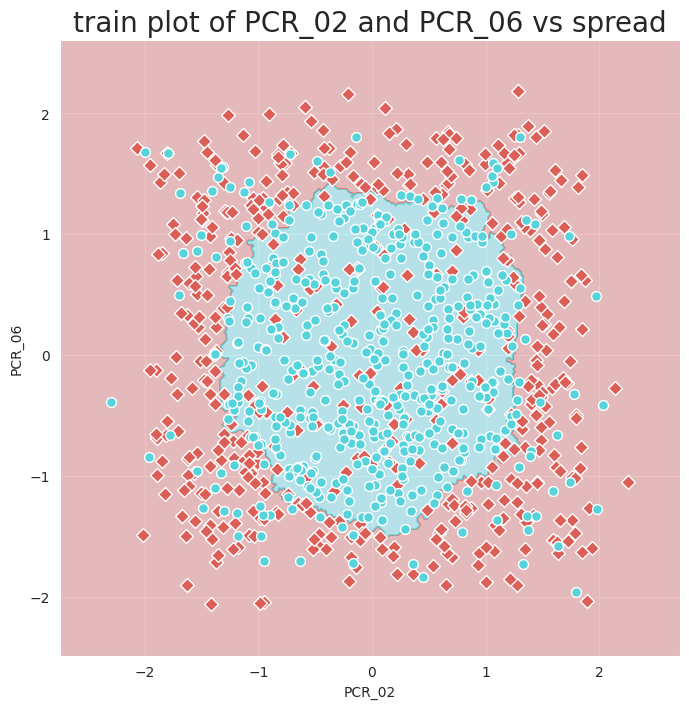

In [9]:
clf = KNeighborsClassifier(n_neighbors=best_k)
clf.fit(XTrainSetPcr26, YTrainSetPcr26)
visualize_clf(clf, X=XTrainSetPcr26, Y=YTrainSetPcr26, 
              title="train plot of PCR_02 and PCR_06 vs spread"
              , xlabel="PCR_02", ylabel="PCR_06")

In [10]:
train_score ,test_score= clf.score(X = XTrainSetPcr26,y = YTrainSetPcr26),clf.score(X = XTestSetPcr26,y = YTestSetPcr26)
train_score ,test_score

(0.783, 0.752)

# PART 2


In [11]:
XtrainSet_0104, YtrainSet_0104 = train_set[['PCR_01', 'PCR_04', 'SpecialProperty']], train_set['risk']
XtestSet_0104, YtestSet_0104 = test_set[['PCR_01', 'PCR_04', 'SpecialProperty']], test_set['risk']

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree.fit(X=XtrainSet_0104, y=YtrainSet_0104)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

[Text(0.5, 0.875, 'PCR_04 <= -0.37\nentropy = 1.0\nsamples = 1000\nvalue = [496, 504]\nclass = 1'),
 Text(0.25, 0.625, 'SpecialProperty <= 0.5\nentropy = 0.917\nsamples = 379\nvalue = [126.0, 253.0]\nclass = 1'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'PCR_04 <= -0.92\nentropy = 0.748\nsamples = 206\nvalue = [44, 162]\nclass = 1'),
 Text(0.0625, 0.125, 'entropy = 0.435\nsamples = 123\nvalue = [11, 112]\nclass = 1'),
 Text(0.1875, 0.125, 'entropy = 0.97\nsamples = 83\nvalue = [33.0, 50.0]\nclass = 1'),
 Text(0.375, 0.375, 'PCR_01 <= -1.137\nentropy = 0.998\nsamples = 173\nvalue = [82, 91]\nclass = 1'),
 Text(0.3125, 0.125, 'entropy = 0.206\nsamples = 31\nvalue = [30, 1]\nclass = -1'),
 Text(0.4375, 0.125, 'entropy = 0.948\nsamples = 142\nvalue = [52, 90]\nclass = 1'),
 Text(0.75, 0.625, 'PCR_01 <= -1.164\nentropy = 0.973\nsamples = 621\nvalue = [370, 251]\nclass = -1'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'SpecialProperty <= 0.5\nentropy = 0.977\nsamples = 90\n

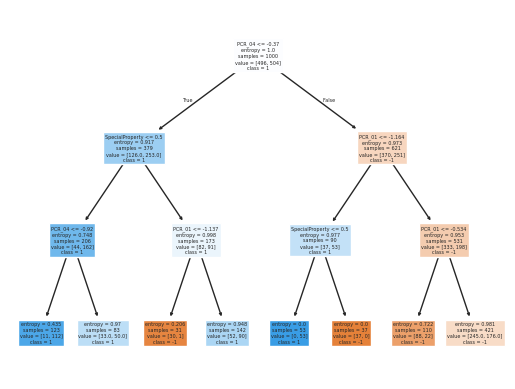

In [13]:
plot_tree(decision_tree=tree,
                       filled=True,
                       class_names=["-1", "1"],
                       feature_names=["PCR_01", "PCR_04", "SpecialProperty"])

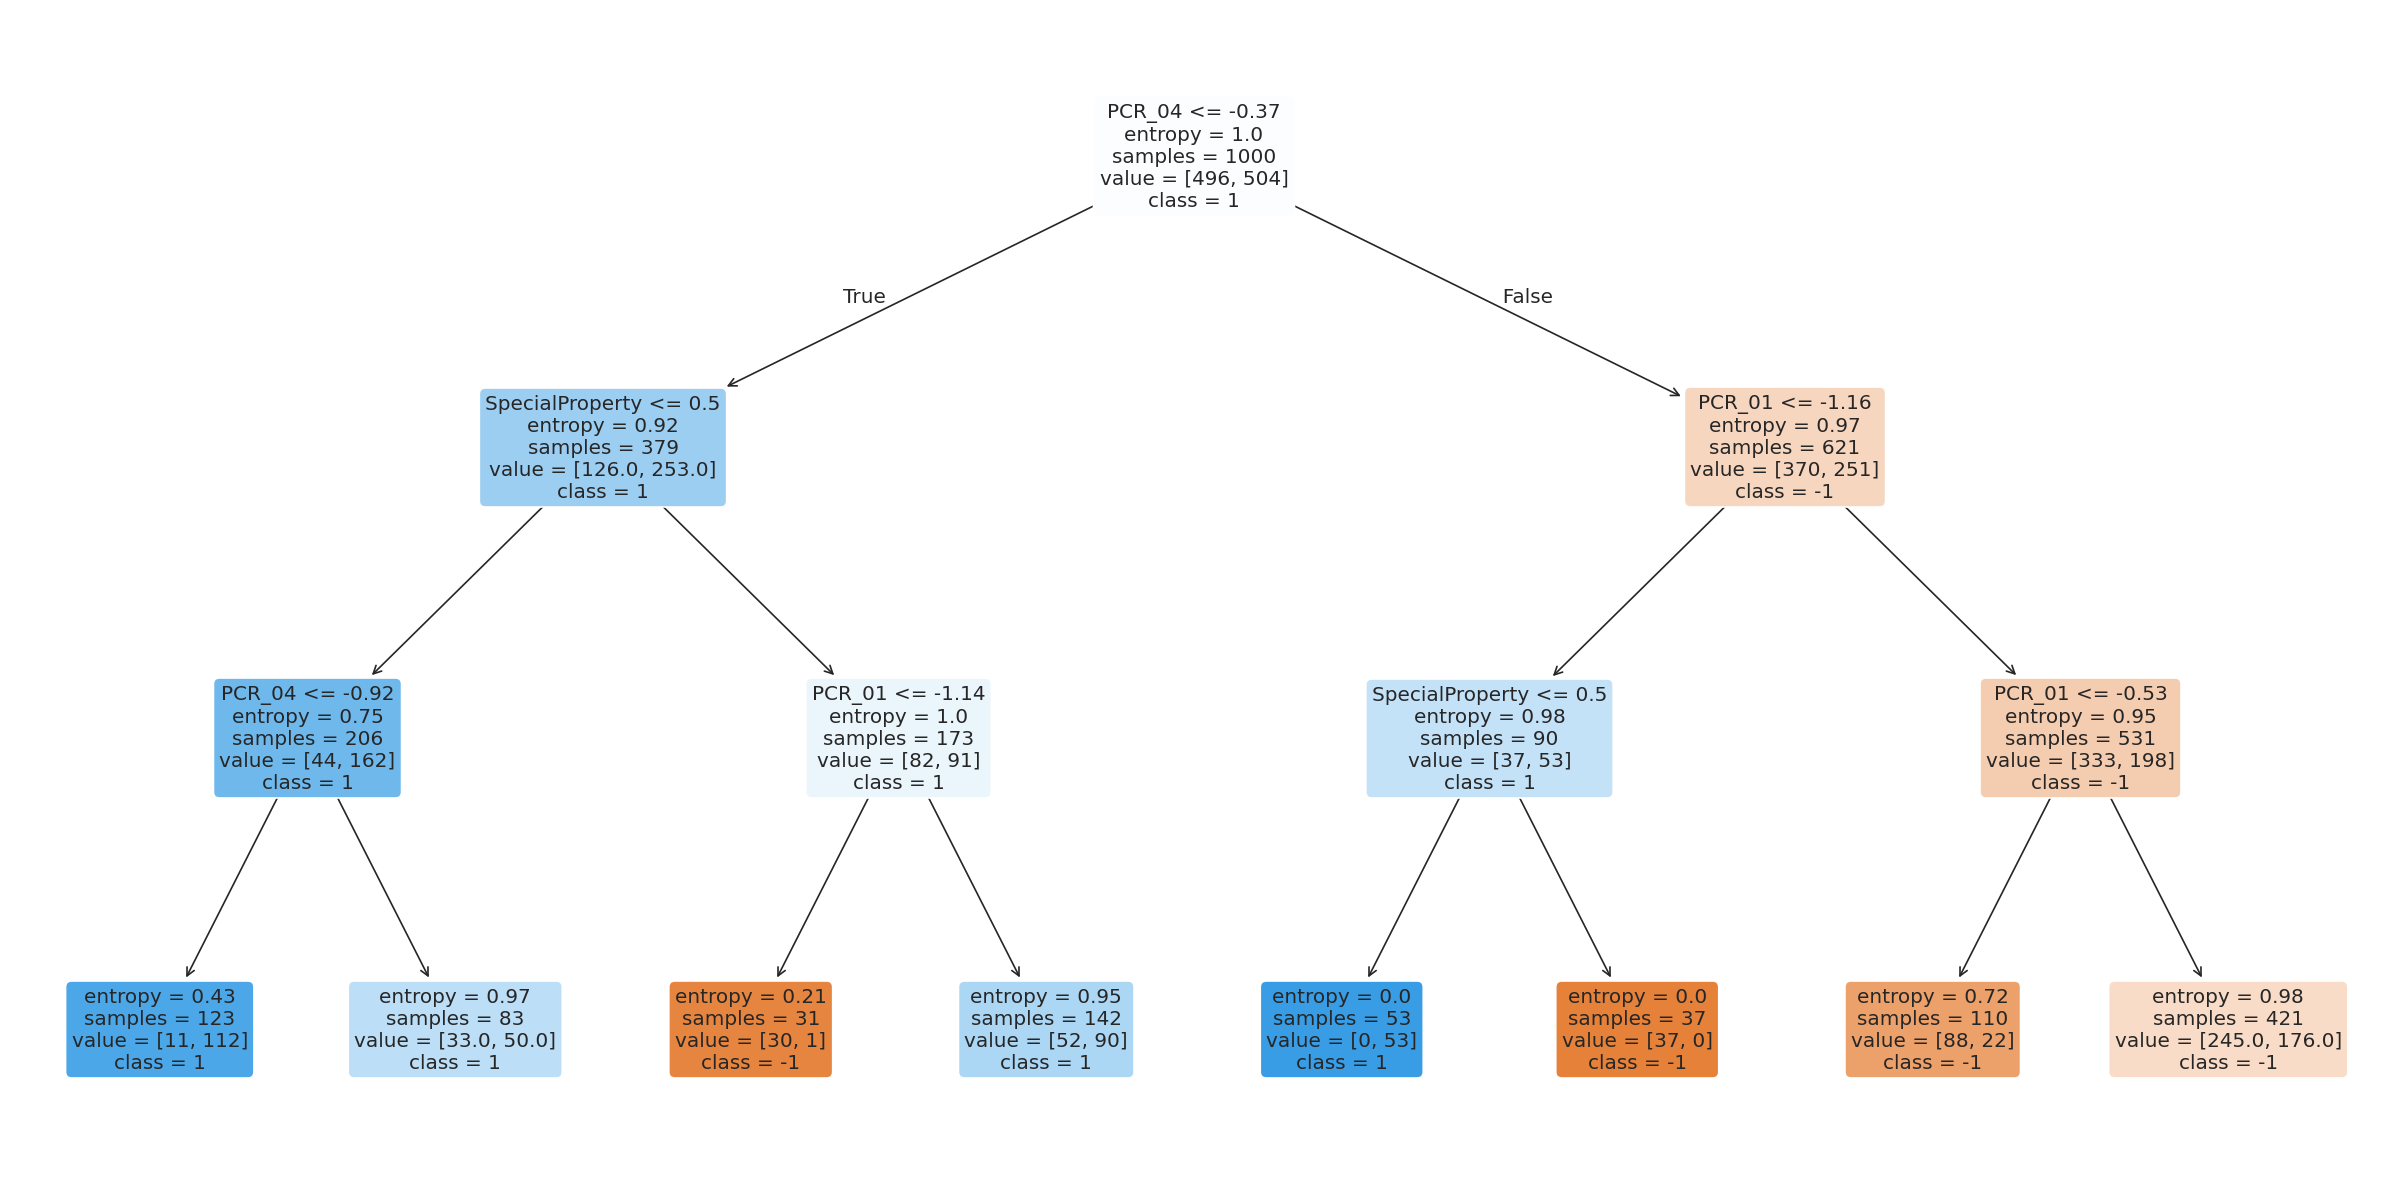

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10), dpi=120)        # make the canvas big and high-res
plot_tree(
    tree,
    feature_names=["PCR_01", "PCR_04", "SpecialProperty"],
    class_names=["-1", "1"],
    filled=True,
    rounded=True,                            # softer, rounded box corners
    fontsize=12,                             # bigger font for readability
    precision=2                              # fewer decimals in split thresholds
)
plt.tight_layout()                          # clean up any overlap
plt.show()


In [15]:
tree.score(X=XtrainSet_0104, y=YtrainSet_0104)

0.705

In [16]:
tree.score(X=XtestSet_0104, y=YtestSet_0104)

0.736

In [17]:
grid = {
    "max_depth": np.arange(5, 30, 1),
    "min_samples_leaf": np.arange(1, 15, 1),
}

In [25]:
from sklearn.model_selection import GridSearchCV
clf_tree = DecisionTreeClassifier(criterion='entropy', random_state=42)

gridSearch_tree = GridSearchCV(estimator=clf_tree,
                               param_grid=grid,
                               cv=5,
                               scoring='accuracy',
                               verbose=2
                                ,n_jobs=-1
                               )
gridSearch_tree.fit(X=XtrainSet_0104, y=YtrainSet_0104)

Fitting 5 folds for each of 350 candidates, totalling 1750 fits
[CV] END ....................max_depth=5, min_samples_leaf=1; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=6; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=6; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=7; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=7; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=8; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_leaf=10; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_leaf=11; total time=   0.0s
[CV] END ...................max_depth=5, min_

GridSearchCV(cv=5,
             estimator=DecisionTreeClassifier(criterion='entropy',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': array([ 5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21,
       22, 23, 24, 25, 26, 27, 28, 29]),
                         'min_samples_leaf': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])},
             scoring='accuracy', verbose=2)

In [19]:
gridSearch_tree.score(X=XtrainSet_0104, y=YtrainSet_0104)

0.856

In [20]:
gridSearch_tree.score(X=XtestSet_0104, y=YtestSet_0104)

0.812

Fitting 5 folds for each of 350 candidates, totalling 1750 fits
[CV] END ....................max_depth=5, min_samples_leaf=1; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=7; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=8; total time=   0.0s
[CV] END ....................max_depth=5, min_samples_leaf=9; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_leaf=10; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_leaf=12; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_leaf=14; total time=   0.0s
[CV] END ....................max_depth=6, min_samples_leaf=2; total time=   0.0s
[CV] END ....................max_depth=6, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=6, min_samples_leaf=8; total time=   0.0s
[CV] END ....................max_depth=6, min_samples_leaf=8; total time=   0.0s
[CV] END ....................max_depth=7, min

/home/dandan/.local/lib/python3.10/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


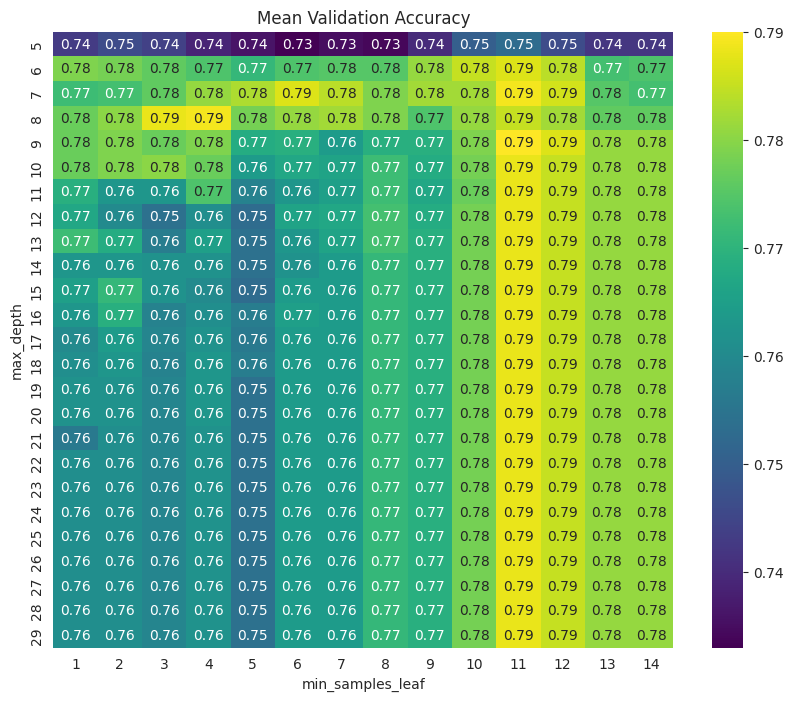

In [21]:
from seaborn import heatmap
gridSearch_tree.fit(X= XtrainSet_0104, y= YtrainSet_0104)

results = pd.DataFrame(gridSearch_tree.cv_results_)

heatmap_data = results.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score')
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data,
            cmap='viridis',
            annot=True,
            fmt=".2f")
plt.title('Mean Validation Accuracy')
plt.xlabel('min_samples_leaf')
plt.ylabel('max_depth')
plt.show()

In [22]:
clf = DecisionTreeClassifier(criterion="entropy",random_state=42)
# GridSearchCV
gs_clf = GridSearchCV(estimator=clf,
                      param_grid=grid,
                      cv=5,
                      verbose=1,
                      scoring='accuracy',  # Ensure we are scoring by accuracy
                      return_train_score= True
                     )

# fit the grid search CV version of clf
gs_clf.fit(X = XtrainSet_0104,y = YtrainSet_0104)

# Get results into a DataFrame
results = pd.DataFrame(gs_clf.cv_results_)

# Reshape results to get a matrix suitable for a heatmap
heatmap_data = results.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_train_score')

# Draw the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap='viridis')
plt.title('Mean Training Accuracy')
plt.xlabel('min_samples_leaf')
plt.ylabel('max_depth')
plt.show()


Fitting 5 folds for each of 350 candidates, totalling 1750 fits
[CV] END ....................max_depth=8, min_samples_leaf=2; total time=   0.0s
[CV] END ....................max_depth=8, min_samples_leaf=2; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=4; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=4; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=4; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=4; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=5; total time=   0.0s
[CV] END ....................max_depth=9, min_samples_leaf=5; total time=   0.0s
[CV] END ...................max_depth=12, min_samples_leaf=2; total time=   0.0s
[CV] END ...................max_depth=12, min

KeyboardInterrupt: 

In [ ]:
gs_clf.best_params_,gs_clf.best_score_

In [ ]:
clf = DecisionTreeClassifier(max_depth=11,
                             min_samples_leaf=9,
                             criterion="entropy",
                             random_state=42)
clf.fit(X = XtrainSet_0104,y = YtrainSet_0104)
clf.score(X = XtrainSet_0104,y = YtrainSet_0104),clf.score(X = XtestSet_0104,y = YtestSet_0104)

# part 3 linear SVM and the polynomial kernel

In [ ]:
#extract the data
Xtrain_PCR_0206, Ytrain_PCR_0206 = train_set[['PCR_02', 'PCR_06']], train_set['spread']
Xtest_PCR_0206, Ytest_PCR_0206 = test_set[['PCR_02', 'PCR_06']], test_set['spread']

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np

class SoftSVM(BaseEstimator, ClassifierMixin):
    """
    Custom C-Support Vector Classification.
    """
    def __init__(self, C: float, lr: float = 1e-5, batch_size = 32):
        """
        Initialize an instance of this class.
        ** Do not edit this method **

        :param C: inverse strength of regularization. Must be strictly positive.
        :param lr: the SGD learning rate (step size)
        """
        self.C = C
        self.lr = lr
        self.batch_size = batch_size
        self.w = None
        self.b = 0.0

    # Initialize a random weight vector
    def init_solution(self, n_features: int):
        """
        Randomize an initial solution (weight vector)
        ** Do not edit this method **

        :param n_features:
        """
        self.w = np.random.randn(n_features)
        self.b = 0.0

    @staticmethod
    def loss(w, b: float, C: float, X, y):
        """
        Compute the SVM objective loss.

        :param w: weight vector for linear classification; array of shape (n_features,)
        :param b: bias scalar for linear classification
        :param C: inverse strength of regularization. Must be strictly positive.
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: the Soft SVM objective loss (float scalar)
        """
        
        margins = (X.dot(w) + b).reshape(-1, 1)
        hinge_inputs = np.multiply(margins, y.reshape(-1, 1))

        norm = np.linalg.norm(w)

        # TODO: complete the loss calculation
        hinge_val = np.maximum(0, 1 - hinge_inputs)
        loss = norm**2 + C * np.sum(hinge_val)
        return loss



    @staticmethod
    def subgradient(w, b: float, C: float, X, y):
        """
        Compute the (analytical) SVM objective sub-gradient.

        :param w: weight vector for linear classification; array of shape (n_features,)
        :param b: bias scalar for linear classification
        :param C: inverse strength of regularization. Must be strictly positive.
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: a tuple with (the gradient of the weights, the gradient of the bias)
        """
        # TODO: calculate the analytical sub-gradient of soft-SVM w.r.t w and b
        if isinstance(X, pd.DataFrame):
            X = X.to_numpy()
        if isinstance(y, pd.Series):
            y = y.to_numpy()
    
        margine = X.dot(w) + b
        hinge_inputs = np.multiply(margine, y)
        f = np.where(hinge_inputs < 1, -1.0, 0.0)
        before_sum = np.multiply(f, y)
        
        g_w = 2*w + C * (X.T.dot(before_sum))
        g_b = C * np.sum(before_sum)
        return g_w, g_b

    def fit_with_logs(self, X, y, max_iter: int = 2000, keep_losses: bool = True):
        """
        Fit the model according to the given training data.

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets (+1 and -1); array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        :param keep_losses:
        :return: the training losses and accuracies during training
        """
        # Initialize learned parameters
        self.init_solution(X.shape[1])

        losses = []
        accuracies = []

        if keep_losses:
            losses.append(self.loss(self.w, self.b, self.C, X, y))
            accuracies.append(self.score(X, y))

        permutation = np.random.permutation(len(y))
        X = X[permutation, :]
        y = y[permutation]
        
        # Iterate over batches
        for iter in range(0, max_iter):
            start_idx = (iter * self.batch_size) % X.shape[0]
            end_idx = min(X.shape[0], start_idx + self.batch_size)
            batch_X = X[start_idx:end_idx, :]
            batch_y = y[start_idx:end_idx]

            # TODO: Compute the (sub)gradient of the current *batch*
            g_w, g_b = self.subgradient(self.w, self.b, self.C, batch_X, batch_y)

            # Perform a (sub)gradient step
            # TODO: update the learned parameters correctly
            self.w -= self.lr * g_w
            self.b -= self.lr * g_b

            if keep_losses:
                losses.append(self.loss(self.w, self.b, self.C, X, y))
                accuracies.append(self.score(X, y))

        return losses, accuracies

    def fit(self, X, y, max_iter: int = 2000):
        """
        Fit the model according to the given training data.
        ** Do not edit this method **

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets (+1 and -1); array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        """
        self.fit_with_logs(X, y, max_iter=max_iter, keep_losses=False)

        return self

    def predict(self, X):
        """
        Perform classification on samples in X.

        :param X: samples for prediction; array of shape (n_samples, n_features)
        :return: Predicted class labels for samples in X; array of shape (n_samples,)
                 NOTE: the labels must be either +1 or -1
        """
        # TODO: compute the predicted labels (+1 or -1)
        y_pred = np.sign(X.dot(self.w) + self.b)

        return y_pred


In [ ]:
def numerical_subgradient(w, b, C, X, y, delta=1e-4):
    w_ = w.copy()
    g_w = np.zeros_like(w_)
    orig_objective = SoftSVM.loss(w_, b, C, X, y)
    for i in range(g_w.shape[0]):
        w_[i] += delta
        perturbed_objective = SoftSVM.loss(w_, b, C, X, y)
        w_[i] -= delta
        g_w[i] = (perturbed_objective - orig_objective) / delta

    g_b = (SoftSVM.loss(w_, b + delta, C, X, y) - orig_objective) / delta
    return g_w, g_b



def compare_gradients(X, y, deltas, C=1, REPEATS=100, figsize=(10, 6)):
    residual_means = []

    for delta in deltas:
        residuals = []

        for _ in range(REPEATS):
            # Randomize vectors in which the gradient is computed
            w = np.random.randn(X.shape[1])
            b = np.random.randn(1)

            # Compute the two types of gradients
            analytic_grad = SoftSVM.subgradient(w, b, C, X, y)[0]
            numeric_grad = numerical_subgradient(w, b, C, X, y, delta=delta)[0]

            residual = np.linalg.norm(numeric_grad - analytic_grad)
            residuals.append(residual)

        residual_means.append(np.mean(residuals))

    plt.figure(figsize=figsize)
    plt.title('Residuals of analytical and numerical gradients', fontsize=22)
    plt.plot(deltas, residual_means, linewidth=3)      
    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('$\delta$', fontsize=18)
    plt.ylabel(r'$\left\Vert \nabla_{w}p_{C}\left(w,b\right) - u_{\delta} \left(w,b\right)\right\Vert$', fontsize=18)

    plt.grid(alpha=0.5)
    plt.show()


In [ ]:
X_train = Xtrain_PCR_0206.values
y_train = Ytrain_PCR_0206.values

compare_gradients(X_train, y_train, deltas=np.logspace(-5, 0, 10))

In [ ]:
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
C=1e5
lrRange = np.logspace(-11, -3, 5)
for lr in lrRange:
    clf = SoftSVM(C=C, lr=lr)
    X_train_poly = PolynomialFeatures(degree=3,).fit_transform(X_train)
    X_train_poly = MinMaxScaler(feature_range=(-1,1)).fit_transform(X_train_poly)
    losses, accuracies = clf.fit_with_logs(X_train_poly, y_train, max_iter=5000)
    plt.figure(figsize=(13, 6))
    plt.subplot(121), plt.grid(alpha=0.5), plt.title ("Training Loss")
    plt.semilogy(losses), plt.xlabel("Step"), plt.ylabel("Loss")
    plt.subplot(122), plt.grid(alpha=0.5), plt.title ("Training Accuracy")
    plt.plot(accuracies), plt.xlabel("Step"), plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.show()
    print(f"the learning rate is: {lr}")
    print(f"the accuracy is: {accuracies[-1]}")
    print(f"the loss is: {losses[-1]}")


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
svm_clf = Pipeline([('feature_mapping', PolynomialFeatures(degree=3)),
('scaler', MinMaxScaler()),
('SVM', SoftSVM(C=1e5, lr=1e-7))])
svm_clf.fit(X_train, y_train)

In [ ]:
visualize_clf(clf = svm_clf
            ,X=X_train, Y=y_train,
            title="plot of PCR 02 & PCR 06 vs spreaqd"
            ,xlabel="PCR 02"
            ,ylabel="PCR 06" )

In [ ]:
train_score, test_score = svm_clf.score(Xtrain_PCR_0206, Ytrain_PCR_0206), svm_clf.score(Xtest_PCR_0206, Ytest_PCR_0206)
print(f"train score: {train_score}, test score: {test_score}")

# part 4 the RBF kernel

In [ ]:
from sklearn.svm import SVC
c = 1
gamma = 1e-7
RBF_kernel = SVC(C=c, kernel='rbf', gamma=gamma)
RBF_kernel.fit(X=Xtrain_PCR_0206, y=Ytrain_PCR_0206)

In [ ]:
visualize_clf(clf=RBF_kernel
              ,X=Xtrain_PCR_0206
              ,Y=Ytrain_PCR_0206
              ,title="RBF kernel plot PCR_02 & PCR_06 vs spreaqd"
              ,xlabel="PCR 02"
              ,ylabel="PCR 06" )

In [ ]:
train_accuracy = RBF_kernel.score(Xtrain_PCR_0206, Ytrain_PCR_0206)
test_accuracy= RBF_kernel.score(Xtest_PCR_0206, Ytest_PCR_0206)
print(f"train accuracy is: {train_accuracy}, test accuracy is: {test_accuracy}")

In [ ]:
from sklearn.svm import SVC
c = 1
gamma = 1
RBF_kernel = SVC(C=c, kernel='rbf', gamma=gamma)
RBF_kernel.fit(X=Xtrain_PCR_0206, y=Ytrain_PCR_0206)

In [ ]:
visualize_clf(clf=RBF_kernel
              ,X=Xtrain_PCR_0206
              ,Y=Ytrain_PCR_0206
              ,title="RBF kernel plot PCR_02 & PCR_06 vs spreaqd"
              ,xlabel="PCR 02"
              ,ylabel="PCR 06" )

In [ ]:
train_accuracy = RBF_kernel.score(Xtrain_PCR_0206, Ytrain_PCR_0206)
test_accuracy= RBF_kernel.score(Xtest_PCR_0206, Ytest_PCR_0206)
print(f"train accuracy is: {train_accuracy}, test accuracy is: {test_accuracy}")

In [ ]:
from sklearn.svm import SVC
c = 1
gamma = 800
RBF_kernel = SVC(C=c, kernel='rbf', gamma=gamma)
RBF_kernel.fit(X=Xtrain_PCR_0206, y=Ytrain_PCR_0206)

In [ ]:
visualize_clf(clf=RBF_kernel
              ,X=Xtrain_PCR_0206
              ,Y=Ytrain_PCR_0206
              ,title="RBF kernel plot PCR_02 & PCR_06 vs spreaqd"
              ,xlabel="PCR 02"
              ,ylabel="PCR 06" )

In [ ]:
train_accuracy = RBF_kernel.score(Xtrain_PCR_0206, Ytrain_PCR_0206)
test_accuracy= RBF_kernel.score(Xtest_PCR_0206, Ytest_PCR_0206)
print(f"train accuracy is: {train_accuracy}, test accuracy is: {test_accuracy}")